# 03 · The Nurse Roster (the showpiece)

The real problem, solved by declaration. Yes/no variables for 'nurse works this shift', and the rules a manager would recognise, each one constraint:

* **coverage** — every shift has enough nurses
* **one-a-day** — at most one shift per nurse per day
* **rest** — no night followed by next morning
* **days off** — everyone gets at least two days off
* **seniority** — only senior nurses cover nights

Then we add a rule in one line, and optimise preferences among valid rosters.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


In [2]:
from dataclasses import replace

from src.datasets import instances
from src.evaluation.correctness import roster_violations, verify_roster
from src.models.nurse_roster import solve_roster
from src.visualisation import roster_heatmap

problem = instances.feasible_roster()
save_json("03_roster_problem", problem)
problem

RosterProblem(num_nurses=6, num_days=7, shifts=('morning', 'evening', 'night'), demand=(1, 1, 1), min_days_off=2, senior_nurses=(0, 1), max_shifts_per_nurse=None, no_back_to_back=True, night_requires_senior=True, preferences=())

## A valid roster in seconds, every rule verified in code

In [3]:
result = solve_roster(problem, time_limit=10.0)
print(result.stats.summary())
assert result.assignment is not None
print("every rule holds:", verify_roster(problem, result.assignment))
print("violations:", roster_violations(problem, result.assignment))

status=OPTIMAL time=0.010s branches=667
every rule holds: True
violations: []


In [4]:
shifts = problem.shifts
schedule = {
    f"nurse {n}": [
        next(
            (shifts[s] for s in range(problem.num_shifts)
             if result.assignment[(n, d, s)] == 1),
            "off",
        )
        for d in range(problem.num_days)
    ]
    for n in range(problem.num_nurses)
}
save_json("03_roster_schedule", {"days": list(range(problem.num_days)), "schedule": schedule})
for nurse, row in schedule.items():
    print(f"{nurse}: " + "  ".join(f"{c:8}" for c in row))

nurse 0: night     off       night     night     night     night     off     
nurse 1: evening   night     evening   evening   off       off       night   
nurse 2: morning   evening   off       morning   off       evening   evening 
nurse 3: off       morning   morning   off       evening   morning   morning 
nurse 4: off       off       off       off       off       off       off     
nurse 5: off       off       off       off       morning   off       off     


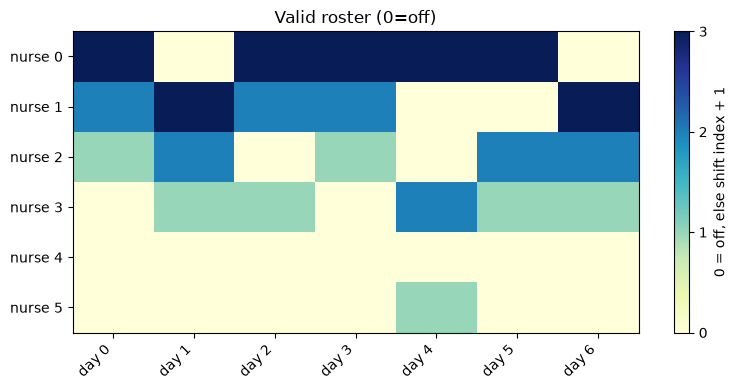

In [5]:
fig = roster_heatmap(problem, result.assignment, title="Valid roster (0=off)")
save_figure("03_roster_heatmap", fig)
plt.show()

## Adding a rule is one line, not a rewrite
The manager now wants **three** guaranteed days off. With a hand-written scheduler that is a re-think. Here it is a single field change — the solver re-searches.

In [6]:
stricter = replace(problem, min_days_off=3)
save_json("03_roster_stricter", stricter)
stricter_result = solve_roster(stricter, time_limit=10.0)
print("still feasible:", stricter_result.is_feasible, "|", stricter_result.stats.status_name)
assert stricter_result.assignment is not None
print("rules still hold:", verify_roster(stricter, stricter_result.assignment))

still feasible: True | OPTIMAL
rules still hold: True


## Optimise among valid rosters
Attach preferences (a nurse would like a particular shift on a particular day) and maximise how many are satisfied — now it is constraint *optimisation*, not just satisfaction.

status: OPTIMAL
satisfied preferences: 4.0 / 4


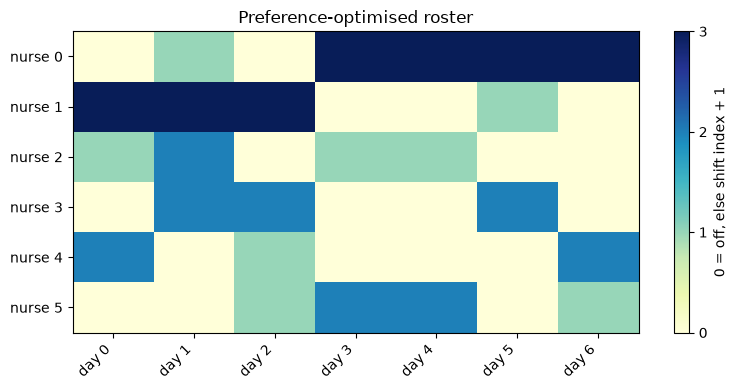

In [7]:
pref = instances.preference_roster()
save_json("03_roster_preferences", {"preferences": [list(p) for p in pref.preferences]})
pref_result = solve_roster(pref, time_limit=10.0)
print("status:", pref_result.stats.status_name)
print("satisfied preferences:", pref_result.stats.objective, "/", len(pref.preferences))
fig = roster_heatmap(pref, pref_result.assignment, title="Preference-optimised roster")
save_figure("03_roster_preferences", fig)
plt.show()

This is the moment a hand-written scheduler is replaced by a declaration: the rules *are* the program, and changing them is changing the rules.